# code_159 · Calibration, missing evidence and validation-chosen deferral

**Book:** section 30.5. Restart and run all cells using the [dedicated Python 3.12 CPU runtime](../CHAPTER_30_RUNTIME.md), not the earlier chapters' 3.14 environment. Explicit hash-verified public model files must be acquired first; ordinary inference is offline. Use the [guide](../CHAPTER_30_GUIDE.md), [execution evidence](../CHAPTER_30_EXECUTION.md), [asset manifest](../CHAPTER_30_ASSETS.md) and [registry](../CODE_EXAMPLES.md#code_159). Prerequisites: structured records, classification/probability and Chapter 8's evidence boundaries. Allow two minutes for execution and30–60 minutes to inspect the contracts.

All states, labels and mechanical examples are generated teaching cases, not field decisions or private records. Named local checkpoints are actually called where declared. No Jev hosted call, account spending or external action occurs. Original typed heads are not named-model substitutes. Output shape, factual correctness, probability calibration and authority to act remain separate questions. Source/development/calibration/final roles are declared locally; generated-instance novelty is not a guarantee of a novel task prior. Neural inference is explicit one-thread CPU float32. The literature cutoff remains18 October 2026.


In [1]:
import platform,time,json,copy,hashlib,sys,warnings
from pathlib import Path
import numpy as np,scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float32);torch.manual_seed(3959);torch.use_deterministic_algorithms(True)
START=time.perf_counter();SEED=3959;rng=np.random.default_rng(SEED);DISCLOSED_WARNINGS=[]
def render_warning(message,category,filename,lineno,file=None,line=None):
    location=filename.split('site-packages/')[-1] if 'site-packages/' in filename else 'code_159'
    DISCLOSED_WARNINGS.append({'category':category.__name__,'message':str(message)})
    print(f'{location}:{lineno}: {category.__name__}: {message}',file=file or sys.stderr)
warnings.showwarning=render_warning
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}
def parameter_digest(network):
    digest=hashlib.sha256()
    for parameter in network.parameters():digest.update(parameter.detach().cpu().numpy().tobytes())
    return digest.hexdigest()


{'python': '3.12.13', 'numpy': '2.5.3', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.1', 'threadpoolctl': '3.7.0', 'torch': '2.8.0'}
CPU: Darwin arm64 seed: 3959


<a id="held-out-calibration-and-deferral"></a>
 ## Fit calibration and select review thresholds before opening final outcomes
 Generate 120 buildings with three members each. The first 60 buildings train a numeric histogram-gradient-boosted tree;20different buildings fit a scalar temperature for both that tree and actual frozen Laya; another 20 buildings choose each deferral threshold; the last 20 buildings supply the final report. Temperatures are selected from a declared grid by calibration log loss. Thresholds maximize development coverage subject to observed error at most0.15 and at least six accepted cases; if none qualifies, defer everything. This empirical constraint is not a population-risk guarantee. Native Laya already uses checkpoint temperatures: this experiment adds task-specific recalibration of returned probabilities, not a claim that the upstream model was uncalibrated or retrained. Final labels never fit temperatures or thresholds.


All declared model/config/tokenizer hashes verified; inference is offline.


tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html


W1021 14:23:27.641000 54650 torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


code_159:28: RuntimeWarning: laya: this checkpoint ships invalid temperatures or values outside [0.5, 5]; using choice:11+=0.10058280825614929 -> 0.5. Treat confidence from the affected entries as uncalibrated.


,model,temperature,development_threshold,development_eligible_thresholds,final_accuracy,raw_final_Brier,calibrated_final_Brier,final_log_loss,final_accepted,final_errors_among_accepted,final_coverage,final_selective_error,final_deferred
0,Laya,4.0,1.00001,0,0.183333,0.810014,0.691919,1.136917,0,0,0.0,NaN,60
1,Tree,1.5,0.00000,8,1.000000,0.000124,0.001728,0.026394,60,0,1.0,0.0,0


Order disagreement: 0.06666666666666667 missing-field disagreement: 0.13333333333333333


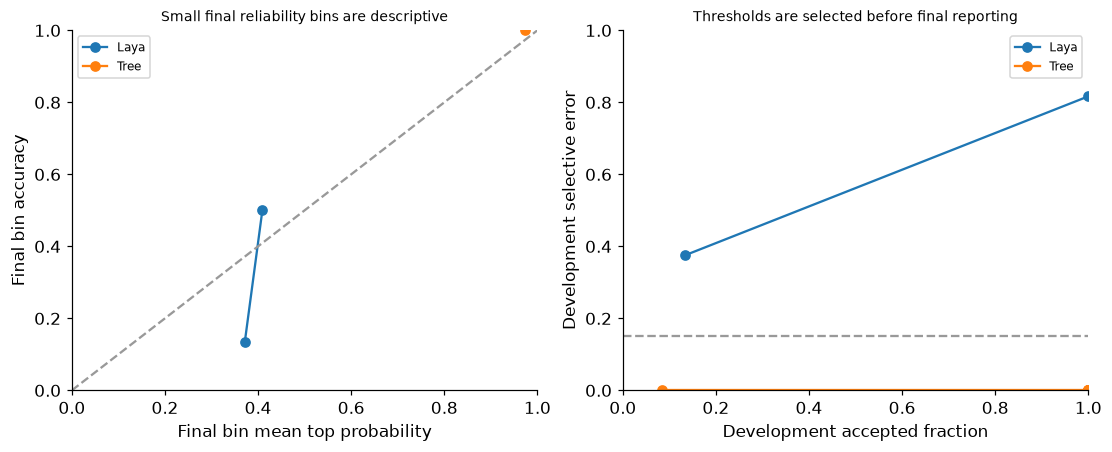

In [2]:
import os,importlib.metadata
ASSET_ROOT=next((root for root in [Path.cwd(),Path.cwd().parent,Path.cwd()/'examples'] if (root/'build/model-cache').is_dir()),Path.cwd().parent)
os.environ['HF_HUB_CACHE']=str(ASSET_ROOT/'build/model-cache');os.environ['HF_HUB_OFFLINE']='1';os.environ['HF_HUB_DISABLE_PROGRESS_BARS']='1';os.environ['TOKENIZERS_PARALLELISM']='false'
ASSETS={'laya': {'repository': 'convaiinnovations/laya', 'revision': '7b928d828b7b0e022f929d9bd2e44165aa270148', 'files': [{'filename': 'README.md', 'bytes': 23187, 'sha256': '00355613796b3f5860b0d5b20392381d26580ec242e04a1fd150c7f116858602', 'cache_relative_path': 'build/model-cache/models--convaiinnovations--laya/snapshots/7b928d828b7b0e022f929d9bd2e44165aa270148/README.md'}, {'filename': 'config.json', 'bytes': 160, 'sha256': '7add7c041b53f7091e65908553af79ab3f077946e5f2312d510ae13b17c7c134', 'cache_relative_path': 'build/model-cache/models--convaiinnovations--laya/snapshots/7b928d828b7b0e022f929d9bd2e44165aa270148/config.json'}, {'filename': 'encoder/config.json', 'bytes': 2083, 'sha256': 'bf3ab80598fdccf414855a2ce80f22859e4492d06ca8a62ddd1cfb63972f8979', 'cache_relative_path': 'build/model-cache/models--convaiinnovations--laya/snapshots/7b928d828b7b0e022f929d9bd2e44165aa270148/encoder/config.json'}, {'filename': 'model.safetensors', 'bytes': 842609210, 'sha256': '891102d372688fc2a094dac56a384bc537b87c63f21f9f3dac0be2b7cbc8d86c', 'cache_relative_path': 'build/model-cache/models--convaiinnovations--laya/snapshots/7b928d828b7b0e022f929d9bd2e44165aa270148/model.safetensors'}, {'filename': 'rl_agent_config.json', 'bytes': 745, 'sha256': 'ae287b56bbcf5f8c4f4541ae9dfd00c914c4c48b940b8398c3058af37ba92bbd', 'cache_relative_path': 'build/model-cache/models--convaiinnovations--laya/snapshots/7b928d828b7b0e022f929d9bd2e44165aa270148/rl_agent_config.json'}, {'filename': 'tokenizer/tokenizer.json', 'bytes': 3583228, 'sha256': '6c8aaa9a542084f2457eab775d4eeb51f92a70c0fd9de28d5edb0ddec3c08d30', 'cache_relative_path': 'build/model-cache/models--convaiinnovations--laya/snapshots/7b928d828b7b0e022f929d9bd2e44165aa270148/tokenizer/tokenizer.json'}, {'filename': 'tokenizer/tokenizer_config.json', 'bytes': 308, 'sha256': '50044de60daaa73df97d262e15a40d4faf0160e7d742df64b377877a1320dd12', 'cache_relative_path': 'build/model-cache/models--convaiinnovations--laya/snapshots/7b928d828b7b0e022f929d9bd2e44165aa270148/tokenizer/tokenizer_config.json'}], 'licence': 'Apache-2.0'}};MODEL_PATHS={}
for name,model in ASSETS.items():
    for file in model['files']:
        path=ASSET_ROOT/file['cache_relative_path']
        if not path.is_file():raise FileNotFoundError('Explicit model acquisition is required: build/chapter30-runtime/bin/python scripts/acquire_chapter30_models.py')
        blob=path.read_bytes();assert len(blob)==file['bytes'] and hashlib.sha256(blob).hexdigest()==file['sha256']
    MODEL_PATHS[name]=path.parents[len(Path(file['filename']).parts)-1]
print('All declared model/config/tokenizer hashes verified; inference is offline.')

NAMES=['routine','soon','urgent']
QUESTIONS={'priority':{'type':'choice','instructions':'Choose the inspection priority using only these constructed rules. Urgent takes precedence.','criteria':{'routine':'Crack width below 0.15 mm, corrosion below 15 percent and inspection age at most 365 days.','soon':'Neither urgent nor routine.','urgent':'Crack width at least 0.40 mm OR corrosion at least 15 percent.'}},'severity':{'type':'score','instructions':'Rate crack width alone using these ordered levels.','criteria':['Crack width below 0.15 mm','Crack width from 0.15 mm up to but excluding 0.40 mm','Crack width at least 0.40 mm']},'wide':{'type':'noul','instructions':'Is crack width at least 0.40 mm?'}}
def generated_states(n):
    states=[]
    for j in range(n):
        level=j%3;states.append({'crack_width_mm':round(float(rng.uniform(*[(.02,.14),(.16,.39),(.45,.8)][level])),2),'corrosion_percent':round(float(rng.uniform(0,20)),1),'inspection_age_days':int(rng.integers(30,550))})
    truth=np.array([2 if s['crack_width_mm']>=.4 or s['corrosion_percent']>=15 else 0 if s['crack_width_mm']<.15 and s['inspection_age_days']<=365 else 1 for s in states]);severity=np.array([0 if s['crack_width_mm']<.15 else 1 if s['crack_width_mm']<.4 else 2 for s in states]);return states,truth,severity

from transformers.utils import logging as transformer_logging
transformer_logging.disable_progress_bar()
from laya import Agent
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import log_loss
VERSIONS.update(laya=importlib.metadata.version('laya'),transformers=importlib.metadata.version('transformers'))
states,truth,severity=generated_states(360);groups=np.repeat(np.arange(120),3);source=groups<60;calibration=(groups>=60)&(groups<80);development=(groups>=80)&(groups<100);final=groups>=100;fields=['crack_width_mm','corrosion_percent','inspection_age_days'];X=np.array([[s[k] for k in fields] for s in states]);assert all(not set(groups[a])&set(groups[b]) for a,b in [(source,calibration),(source,development),(source,final),(calibration,development),(calibration,final),(development,final)])
tree=HistGradientBoostingClassifier(max_iter=100,max_leaf_nodes=7,l2_regularization=1.,random_state=SEED).fit(X[source],truth[source]);agent=Agent(str(MODEL_PATHS['laya']),device='cpu',backend='eager',compile=False);before=parameter_digest(agent.model);evaluation_ids=np.flatnonzero(~source);native=agent.predict_batch([states[i] for i in evaluation_ids],{'priority':QUESTIONS['priority']},batch_size=8);assert all(not r['usage']['truncated'] for r in native)
lp=np.array([[r['answers']['priority']['probabilities'][k] for k in NAMES] for r in native]);lp/=lp.sum(1,keepdims=True);all_laya=np.full((360,3),np.nan);all_laya[evaluation_ids]=lp;returned_confidence=np.array([r['answers']['priority']['confidence'] for r in native]);raw={'Laya':all_laya,'Tree':tree.predict_proba(X)}
def temper(p,t):
    z=np.log(np.clip(p,1e-7,1))/t;z-=z.max(1,keepdims=True);out=np.exp(z);return out/out.sum(1,keepdims=True)
temperatures=[.5,.75,1.,1.5,2.,3.,4.];thresholds=[0.,.4,.5,.6,.7,.8,.9,.95,.99,1.00001];fitted={};rows=[];curves={}
for name,p in raw.items():
    losses=[float(log_loss(truth[calibration],temper(p[calibration],t),labels=[0,1,2])) for t in temperatures];t=temperatures[int(np.argmin(losses))];pc=temper(p[development],t);dev_rows=[]
    for threshold in thresholds:
        accepted=pc.max(1)>=threshold;n=int(accepted.sum());error=float(np.mean(pc.argmax(1)[accepted]!=truth[development][accepted])) if n else None;dev_rows.append({'threshold':threshold,'accepted':n,'error':error})
    eligible=[r for r in dev_rows if r['accepted']>=6 and r['error']<=.15];chosen=max(eligible,key=lambda r:r['accepted'])['threshold'] if eligible else 1.00001;p_final=temper(p[final],t);accept=p_final.max(1)>=chosen;n=int(accept.sum());err=int(np.sum(p_final.argmax(1)[accept]!=truth[final][accept]));risk=err/n if n else None;fitted[name]=(t,chosen,p_final,accept);curves[name]=dev_rows
    rows.append({'model':name,'temperature':t,'development_threshold':chosen,'development_eligible_thresholds':len(eligible),'final_accuracy':float(np.mean(p_final.argmax(1)==truth[final])),'raw_final_Brier':float(np.mean(np.sum((p[final]-np.eye(3)[truth[final]])**2,1))),'calibrated_final_Brier':float(np.mean(np.sum((p_final-np.eye(3)[truth[final]])**2,1))),'final_log_loss':float(log_loss(truth[final],p_final,labels=[0,1,2])),'final_accepted':n,'final_errors_among_accepted':err,'final_coverage':n/60,'final_selective_error':risk,'final_deferred':60-n})
final_states=[states[i] for i in np.flatnonzero(final)];reverse=copy.deepcopy(QUESTIONS['priority']);reverse['criteria']=dict(reversed(list(reverse['criteria'].items())));order_out=agent.predict_batch(final_states,{'priority':reverse},batch_size=8);order_p=np.array([[r['answers']['priority']['probabilities'][k] for k in NAMES] for r in order_out]);order_p/=order_p.sum(1,keepdims=True)
missing_states=[{k:v for k,v in state.items() if k!='crack_width_mm'} for state in final_states];missing_out=agent.predict_batch(missing_states,{'priority':QUESTIONS['priority']},batch_size=8);missing_p=np.array([[r['answers']['priority']['probabilities'][k] for k in NAMES] for r in missing_out]);missing_p/=missing_p.sum(1,keepdims=True)
missing_policy=['review' if set(s)!=set(fields) else 'evaluate_threshold' for s in missing_states];assert set(missing_policy)=={'review'} and before==parameter_digest(agent.model)
order_disagreement=float(np.mean(order_p.argmax(1)!=all_laya[final].argmax(1)));missing_disagreement=float(np.mean(missing_p.argmax(1)!=all_laya[final].argmax(1)));RESULTS.update(source_buildings=60,calibration_buildings=20,development_buildings=20,final_buildings=20,members_per_building=3,temperature_grid=temperatures,threshold_grid=thresholds,development_error_constraint=.15,minimum_development_accepted=6,metrics=rows,development_curves=curves,option_order_final_disagreement=order_disagreement,missing_field_final_disagreement=missing_disagreement,missing_field_policy_reviews=60,laya_returned_confidence_range=[float(returned_confidence.min()),float(returned_confidence.max())],laya_weights_unchanged=True,final_labels_used_for_selection=0);display(pd.DataFrame(rows));print('Order disagreement:',order_disagreement,'missing-field disagreement:',missing_disagreement)
fig,axes=plt.subplots(1,2,figsize=(10,4))
for name,(t,threshold,p,accepted) in fitted.items():
    confidence=p.max(1);correct=p.argmax(1)==truth[final];bins=np.linspace(0,1,6);points=[]
    for lo,hi in zip(bins[:-1],bins[1:]):
        mask=(confidence>=lo)&(confidence<(hi if hi<1 else 1.00001))
        if mask.any():points.append((confidence[mask].mean(),correct[mask].mean(),mask.sum()))
    points=np.array(points);axes[0].plot(points[:,0],points[:,1],marker='o',label=name);curve=curves[name];valid=[r for r in curve if r['error'] is not None];axes[1].plot([r['accepted']/60 for r in valid],[r['error'] for r in valid],marker='o',label=name)
axes[0].plot([0,1],[0,1],color='.6',linestyle='--');axes[0].set(xlim=(0,1),ylim=(0,1),xlabel='Final bin mean top probability',ylabel='Final bin accuracy',title='Small final reliability bins are descriptive');axes[0].legend(fontsize=8);axes[1].axhline(.15,color='.6',linestyle='--');axes[1].set(xlim=(0,1),ylim=(0,1),xlabel='Development accepted fraction',ylabel='Development selective error',title='Thresholds are selected before final reporting');axes[1].legend(fontsize=8);plt.show()


<a id="missing-evidence-is-a-policy-input"></a>
 ## A confident answer does not repair absent measurements
 Reverse the three named criteria without changing their meaning, and separately remove crack width from every final state. Report changed decisions as diagnostics, without selecting a better ordering on final labels. Missing-field predictions are not credited as predictions from a fully observed state; an independent evidence-completeness rule sends all of them to review regardless of returned confidence. This gate is distinct from the development-selected uncertainty threshold. Whole-building splits reduce member overlap, but the 60 final records are still only 20generated groups and the rule is artificial. Calibration plots, observed error limits and rounded native probabilities do not establish performance on inspected structures or future policy changes.


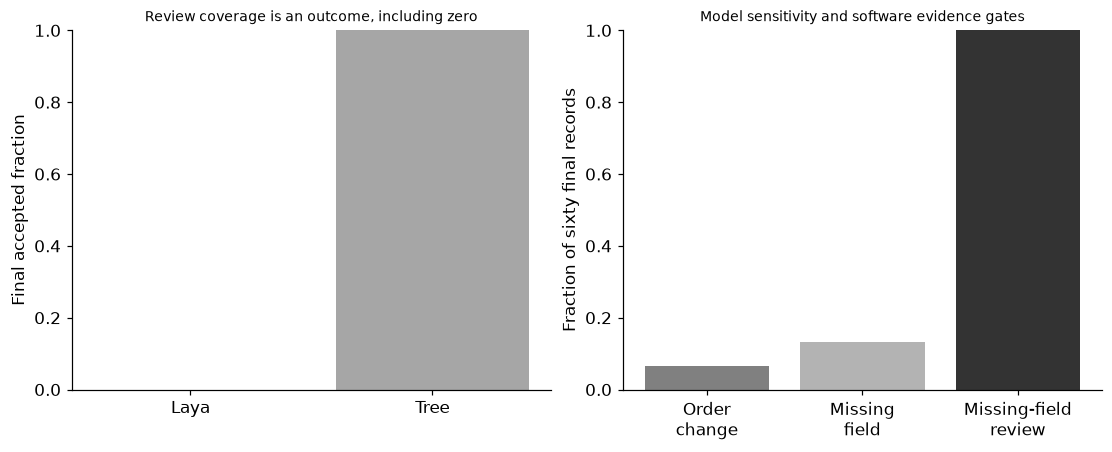

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));xx=np.arange(2);axes[0].bar(xx,[r['final_coverage'] for r in rows],color=['.3','.65']);axes[0].set(xticks=xx,xticklabels=['Laya','Tree'],ylim=(0,1),ylabel='Final accepted fraction',title='Review coverage is an outcome, including zero');axes[1].bar(range(3),[order_disagreement,missing_disagreement,1.],color=['.5','.7','.2']);axes[1].set(xticks=range(3),xticklabels=['Order\nchange','Missing\nfield','Missing-field\nreview'],ylim=(0,1),ylabel='Fraction of sixty final records',title='Model sensitivity and software evidence gates');plt.show()
assert len(rows)==2 and all(r['final_accepted']+r['final_deferred']==60 for r in rows) and RESULTS['final_labels_used_for_selection']==0


In [4]:
summary={'example_id':'code_159','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual native Laya probabilities versus a fitted numeric tree control', 'whole-building source calibration development and final evidence roles', 'calibration-only temperature selection and development-only deferral', 'option-order and missing-evidence diagnostics', 'returned confidence separated from observed correctness and policy authority'],'results':RESULTS,'disclosed_warnings':DISCLOSED_WARNINGS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual native Laya probabilities versus a fitted numeric tree control", "whole-building source calibration development and final evidence roles", "calibration-only temperature selection and development-only deferral", "option-order and missing-evidence diagnostics", "returned confidence separated from observed correctness and policy authority"], "disclosed_warnings": [{"category": "TqdmWarning", "message": "IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html"}, {"category": "RuntimeWarning", "message": "laya: this checkpoint ships invalid temperatures or values outside [0.5, 5]; using choice:11+=0.10058280825614929 -> 0.5. Treat confidence from the affected entries as uncalibrated."}], "elapsed_seconds": 36.302, "example_id": "code_159", "hardware": "Darwin arm64 CPU", "results": {"calibration_buildings": 20, "development_buildings": 20, "development_curves": {"La